# Credit Risk Scorecard Project
## Phase 1: Data Loading & Setup

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Display all columns
pd.set_option('display.max_columns', None)

In [ ]:
df = pd.read_csv('/content/cs-training.csv')

In [ ]:
df.shape

(150000, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [ ]:
df.columns

Index(['Unnamed: 0', 'SeriousDlqin2yrs',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

In [ ]:
df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [ ]:
df.rename(columns={
    'Unnamed: 0':'customer_id',
    'RevolvingUtilizationOfUnsecuredLines':'RevolvingUtilization',
    'NumberOfTime30-59DaysPastDueNotWorse':'Times30_59DaysLate',
    'NumberOfOpenCreditLinesAndLoans':'OpenCreditLines',
    'NumberOfTimes90DaysLate':'Times90DaysLate',
    'NumberRealEstateLoansOrLines':'RealEstateLoans',
    'NumberOfTime60-89DaysPastDueNotWorse':'Times60_89DaysLate',
    'NumberOfDependents':'Dependents'
}, inplace=True)

In [ ]:
df.head()

,customer_id,SeriousDlqin2yrs,RevolvingUtilization,age,Times30_59DaysLate,DebtRatio,MonthlyIncome,OpenCreditLines,Times90DaysLate,RealEstateLoans,Times60_89DaysLate,Dependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### Phase 2: Data Quality Assessment

In [ ]:
df.isnull().sum()

,0
customer_id,0
SeriousDlqin2yrs,0
RevolvingUtilization,0
age,0
Times30_59DaysLate,0
DebtRatio,0
MonthlyIncome,29731
OpenCreditLines,0
Times90DaysLate,0
RealEstateLoans,0


In [ ]:
(df.isnull().sum()/len(df))*100

,0
customer_id,0.000000
SeriousDlqin2yrs,0.000000
RevolvingUtilization,0.000000
age,0.000000
Times30_59DaysLate,0.000000
DebtRatio,0.000000
MonthlyIncome,19.820667
OpenCreditLines,0.000000
Times90DaysLate,0.000000
RealEstateLoans,0.000000


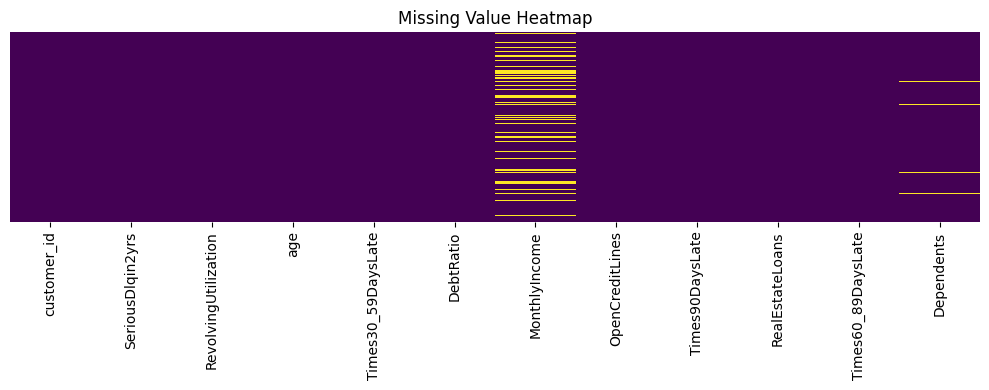

In [ ]:
# Missing value heatmap
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap='viridis')
plt.title("Missing Value Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.dtypes

,0
customer_id,int64
SeriousDlqin2yrs,int64
RevolvingUtilization,float64
age,int64
Times30_59DaysLate,int64
DebtRatio,float64
MonthlyIncome,float64
OpenCreditLines,int64
Times90DaysLate,int64
RealEstateLoans,int64


In [ ]:
#Removing Null
df["MonthlyIncome"] = df["MonthlyIncome"].fillna(df["MonthlyIncome"].median())

df["Dependents"] = df['Dependents'].fillna(0)

In [ ]:
df.isnull().sum()

,0
customer_id,0
SeriousDlqin2yrs,0
RevolvingUtilization,0
age,0
Times30_59DaysLate,0
DebtRatio,0
MonthlyIncome,0
OpenCreditLines,0
Times90DaysLate,0
RealEstateLoans,0


In [ ]:
df[df['age'] == 0]

,customer_id,SeriousDlqin2yrs,RevolvingUtilization,age,Times30_59DaysLate,DebtRatio,MonthlyIncome,OpenCreditLines,Times90DaysLate,RealEstateLoans,Times60_89DaysLate,Dependents
65695,65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


In [ ]:
df = df[df['age'] != 0]

The row with age 0 has been removed. You can verify this by checking `df[df['age'] == 0]` again, which should now return an empty DataFrame.

In [ ]:
(df["RevolvingUtilization"]>1).sum()

np.int64(3321)

In [ ]:
df["RevolvingUtilization"] = np.where(df["RevolvingUtilization"] > 1, 1, df["RevolvingUtilization"])

In [ ]:
# Verify the capping by checking the maximum value and the count of values greater than 1
display(df["RevolvingUtilization"].describe())
print(f"Number of 'RevolvingUtilization' values still greater than 1: {(df['RevolvingUtilization'] > 1).sum()}")

,RevolvingUtilization
count,149999.000000
mean,0.319191
std,0.349478
min,0.000000
25%,0.029867
50%,0.154176
75%,0.559044
max,1.000000


Number of 'RevolvingUtilization' values still greater than 1: 0


In [ ]:
(df["Times90DaysLate"]==98).sum()

np.int64(264)

In [ ]:
#Checking if there any Times90DaysLate == 98 exists
display(df["Times90DaysLate"].describe())
print(f"Number of 'Times90DaysLate' values still equql to 98: {(df['Times90DaysLate'] ==98).sum()}")

,Times90DaysLate
count,149999.000000
mean,0.265975
std,4.169318
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,98.000000


Number of 'Times90DaysLate' values still equql to 98: 264


In [ ]:
df["Times90DaysLate"] = np.where(df["Times90DaysLate"] == 98, np.nan, df["Times90DaysLate"])

In [ ]:
df['Times90DaysLate'].isnull().sum()

np.int64(264)

In [ ]:
# As we replaced Times90DaysLate==98 to null, we now replace those null values with the median.
df["Times90DaysLate"] = df["Times90DaysLate"].fillna(df["Times90DaysLate"].median())

In [ ]:
#Verifying Cleaning
df.isnull().sum()

,0
customer_id,0
SeriousDlqin2yrs,0
RevolvingUtilization,0
age,0
Times30_59DaysLate,0
DebtRatio,0
MonthlyIncome,0
OpenCreditLines,0
Times90DaysLate,0
RealEstateLoans,0


In [ ]:
#Percentage of customer defaulted
default_rate = df["SeriousDlqin2yrs"].mean()*100

print(default_rate)

6.684044560297068


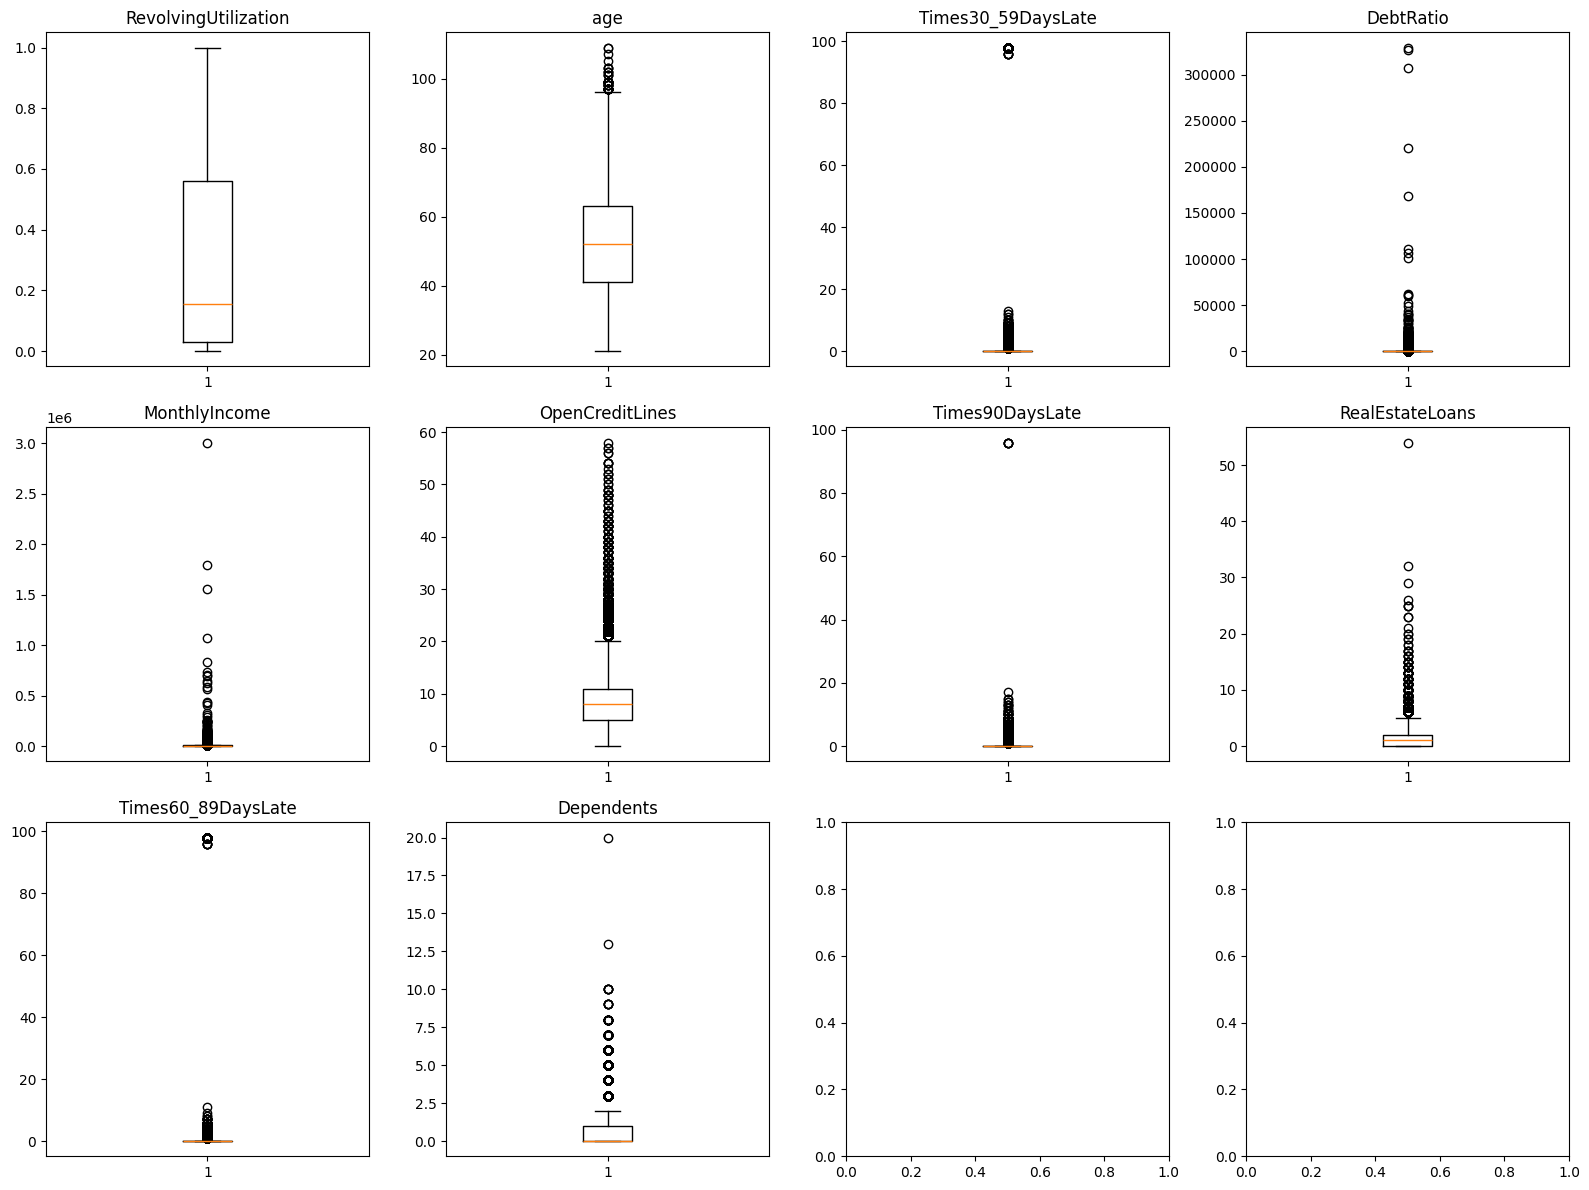

MonthlyIncome 99th percentile: 23000.0
DebtRatio 99th percentile: 4979.079999999958


In [ ]:
#Outlier Analysis
#Check distributions with boxplots
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

cols = ['RevolvingUtilization', 'age', 'Times30_59DaysLate', 'DebtRatio',
        'MonthlyIncome', 'OpenCreditLines', 'Times90DaysLate',
        'RealEstateLoans', 'Times60_89DaysLate', 'Dependents']

for i, col in enumerate(cols):
    axes[i].boxplot(df[col].dropna())
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

# Check extreme values in MonthlyIncome and DebtRatio
print("MonthlyIncome 99th percentile:", df['MonthlyIncome'].quantile(0.99))
print("DebtRatio 99th percentile:", df['DebtRatio'].quantile(0.99))

# Cap MonthlyIncome and DebtRatio at 99th percentile
df['MonthlyIncome'] = df['MonthlyIncome'].clip(
    upper=df['MonthlyIncome'].quantile(0.99))
df['DebtRatio'] = df['DebtRatio'].clip(
    upper=df['DebtRatio'].quantile(0.99))

In [ ]:
df["Times30_59DaysLate"].value_counts().sort_index()

,count
Times30_59DaysLate,
0,126018
1,16032
2,4598
3,1754
4,747
5,342
6,140
7,54
8,25


In [ ]:
print(df['Times30_59DaysLate'].value_counts().sort_index(ascending=False).head(20))
print()
print("Max value:", df['Times30_59DaysLate'].max())
print("99th percentile:", df['Times30_59DaysLate'].quantile(0.99))

Times30_59DaysLate
98       264
96         5
13         1
12         2
11         1
10         4
9         12
8         25
7         54
6        140
5        342
4        747
3       1754
2       4598
1      16032
0     126018
Name: count, dtype: int64

Max value: 98
99th percentile: 4.0


In [ ]:
# Replace 96 and 98 — both are encoding artifacts

df['Times30_59DaysLate'] = df['Times30_59DaysLate'].replace([96, 98], np.nan)
df['Times60_89DaysLate'] = df['Times60_89DaysLate'].replace([96, 98], np.nan)

# Verify
print("Nulls after replacement:")
print(df[['Times30_59DaysLate',
          'Times60_89DaysLate']].isnull().sum())

Nulls after replacement:
Times30_59DaysLate    269
Times60_89DaysLate    269
dtype: int64


In [ ]:
for col in ['Times30_59DaysLate', 'Times60_89DaysLate']:
    median_val = df[col].median()
    df[col].fillna(median_val, inplace=True)
    print(f"{col} median used for imputation: {median_val}")
# Median will be 0 for all three — most customers have zero late payments

Times30_59DaysLate median used for imputation: 0.0
Times60_89DaysLate median used for imputation: 0.0


/tmp/ipykernel_993/4035817917.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


In [ ]:
df.isnull().sum()

,0
customer_id,0
SeriousDlqin2yrs,0
RevolvingUtilization,0
age,0
Times30_59DaysLate,0
DebtRatio,0
MonthlyIncome,0
OpenCreditLines,0
Times90DaysLate,0
RealEstateLoans,0


In [ ]:
#Cap Remaining Outliers at 99th Percentile
for col in ['Times30_59DaysLate', 'Times60_89DaysLate', 'Times90DaysLate']:
    p99 = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=p99)
    print(f"{col} capped at {p99}")

Times30_59DaysLate capped at 3.0
Times60_89DaysLate capped at 2.0
Times90DaysLate capped at 2.0


In [ ]:
#Verify Everything is Clean
print("\nAfter all treatment:")
print(df[['Times30_59DaysLate',
          'Times60_89DaysLate',
          'Times90DaysLate']].describe())


After all treatment:
       Times30_59DaysLate  Times60_89DaysLate  Times90DaysLate
count       149999.000000       149999.000000    149999.000000
mean             0.229828            0.059594         0.072700
std              0.601330            0.278262         0.324288
min              0.000000            0.000000         0.000000
25%              0.000000            0.000000         0.000000
50%              0.000000            0.000000         0.000000
75%              0.000000            0.000000         0.000000
max              3.000000            2.000000         2.000000


In [ ]:
# Columns to cap at 99th percentile
cols_to_cap = ['DebtRatio', 'MonthlyIncome', 'OpenCreditLines',
               'RealEstateLoans', 'Dependents']

for col in cols_to_cap:
    p99 = df[col].quantile(0.99)
    df[col] = df[col].clip(upper=p99)
    print(f"{col} capped at {p99:.2f}")

DebtRatio capped at 4979.00
MonthlyIncome capped at 23000.00
OpenCreditLines capped at 24.00
RealEstateLoans capped at 4.00
Dependents capped at 4.00


##Exploratory Data Analysis (EDA)

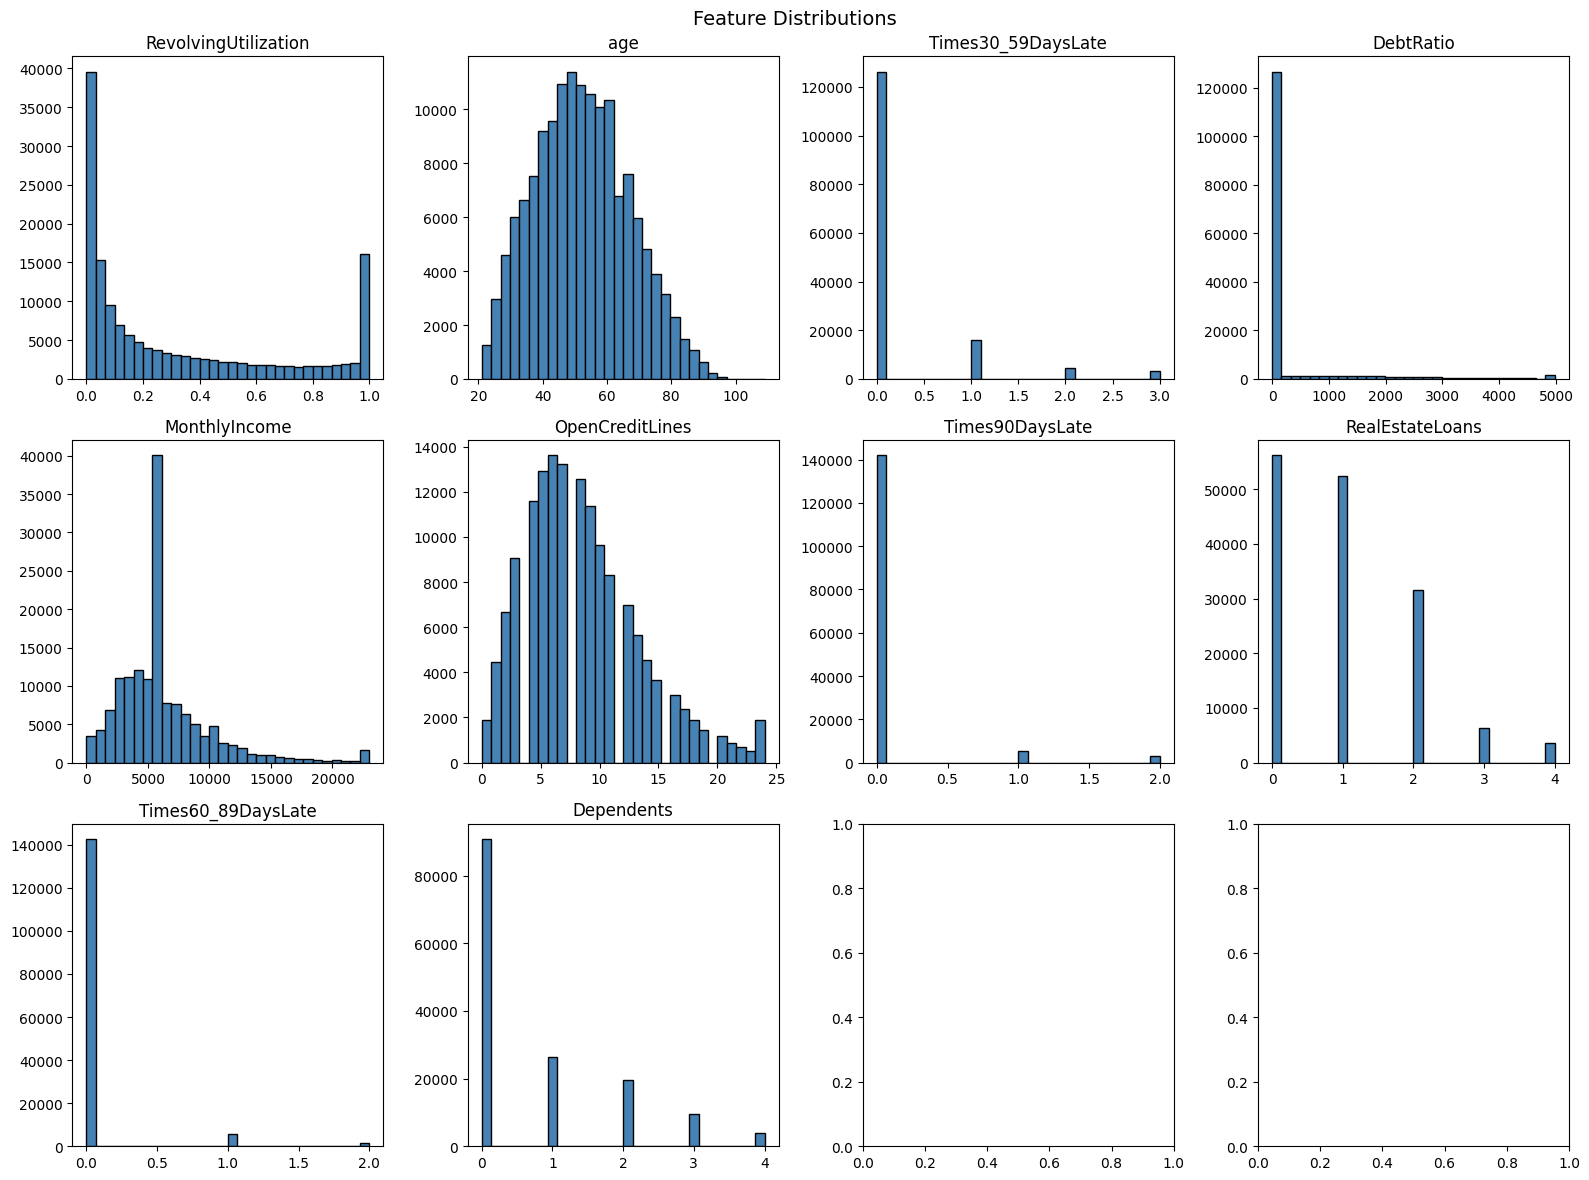

In [ ]:
#Distribution Analysis
# Plot distribution of all features
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(df[col], bins=30, edgecolor='black', color='steelblue')
    axes[i].set_title(col)
    axes[i].set_xlabel('')

plt.suptitle("Feature Distributions", fontsize=14)
plt.tight_layout()
plt.show()

/tmp/ipykernel_993/1641480709.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_default = df.groupby('age_group')['SeriousDlqin2yrs'].mean() * 100


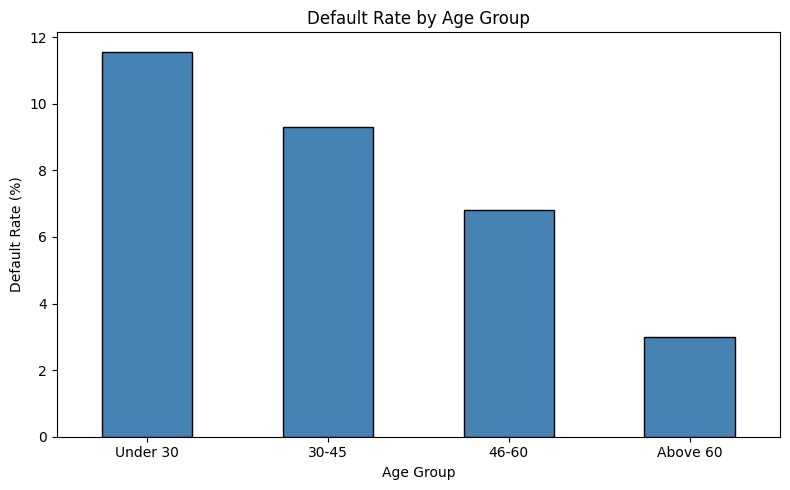

In [ ]:
# Default rate by age group
df['age_group'] = pd.cut(df['age'],
                          bins=[0, 30, 45, 60, 120],
                          labels=['Under 30', '30-45', '46-60', 'Above 60'])

age_default = df.groupby('age_group')['SeriousDlqin2yrs'].mean() * 100

plt.figure(figsize=(8, 5))
age_default.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Default Rate by Age Group")
plt.ylabel("Default Rate (%)")
plt.xlabel("Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

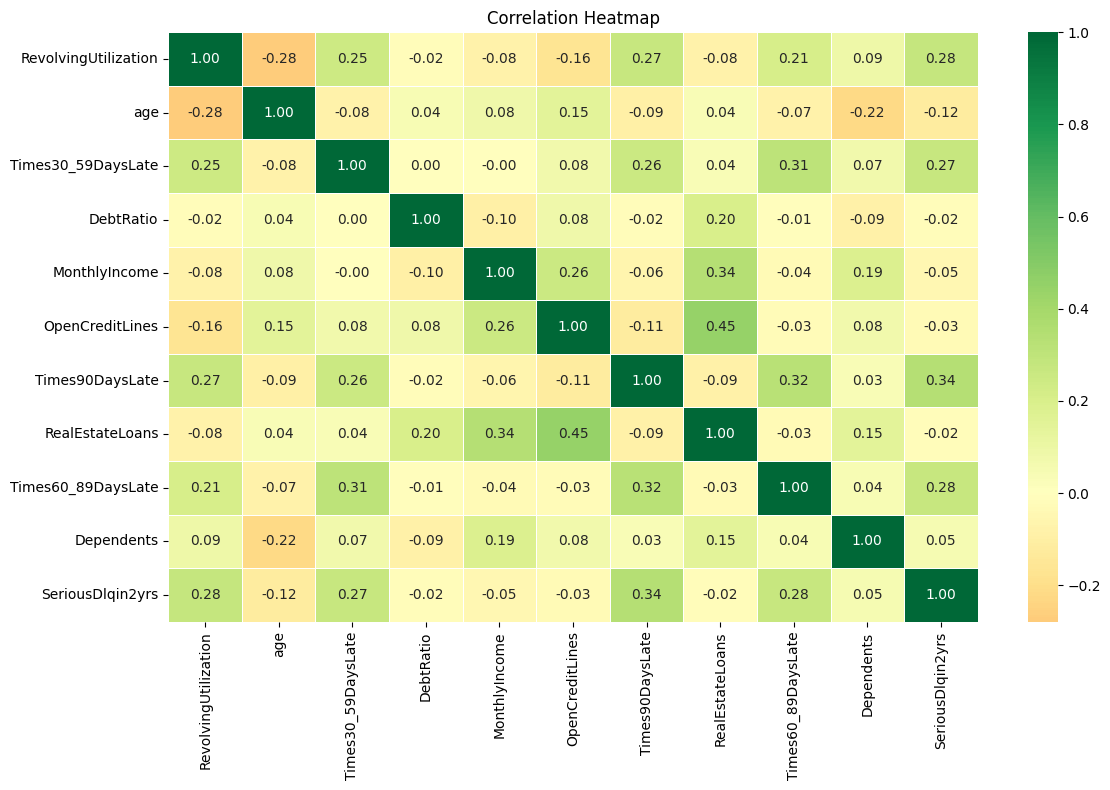

In [ ]:
plt.figure(figsize=(12, 8))
corr = df[cols + ['SeriousDlqin2yrs']].corr()

sns.heatmap(corr,
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            center=0,
            linewidths=0.5)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

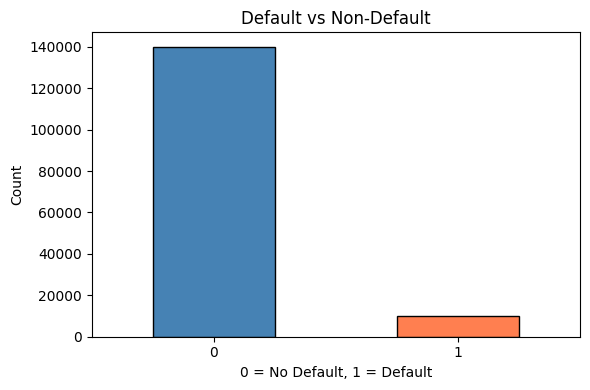

Class distribution:
SeriousDlqin2yrs
0    139973
1     10026
Name: count, dtype: int64
Default rate: 6.684044560297068 %


In [ ]:
# Target variable distribution
#Class Imbalance Visualization
plt.figure(figsize=(6, 4))
df['SeriousDlqin2yrs'].value_counts().plot(
    kind='bar',
    color=['steelblue', 'coral'],
    edgecolor='black')

plt.title("Default vs Non-Default")
plt.xlabel("0 = No Default, 1 = Default")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Class distribution:")
print(df['SeriousDlqin2yrs'].value_counts())
print("Default rate:", df['SeriousDlqin2yrs'].mean() * 100, "%")

In [ ]:
# Create Derived Features
#Total delinquency score
df['total_delinquencies'] = (df['Times30_59DaysLate'] +
                              df['Times60_89DaysLate'] +
                              df['Times90DaysLate'])

# Debt burden score
df['debt_burden'] = df['DebtRatio'] * df['MonthlyIncome']


In [ ]:
#Severe Delinquency Flag
df["severe_delinquency_flag"] = np.where(
    (df["Times90DaysLate"]>=1) &
    (df["Times90DaysLate"]<90),
    1,
    0
)

In [ ]:
#High Utilization Flag
df["high_utilization_flag"] = np.where(
    (df["RevolvingUtilization"]>=0.75) &
    (df["RevolvingUtilization"]<=1),
    1,
    0
)

In [ ]:
# Drop temporary segmentation columns before export
df.drop(columns=['age_group'], inplace=True)

print("age_group column dropped")
print("Current shape:", df.shape)

age_group column dropped
Current shape: (149999, 16)


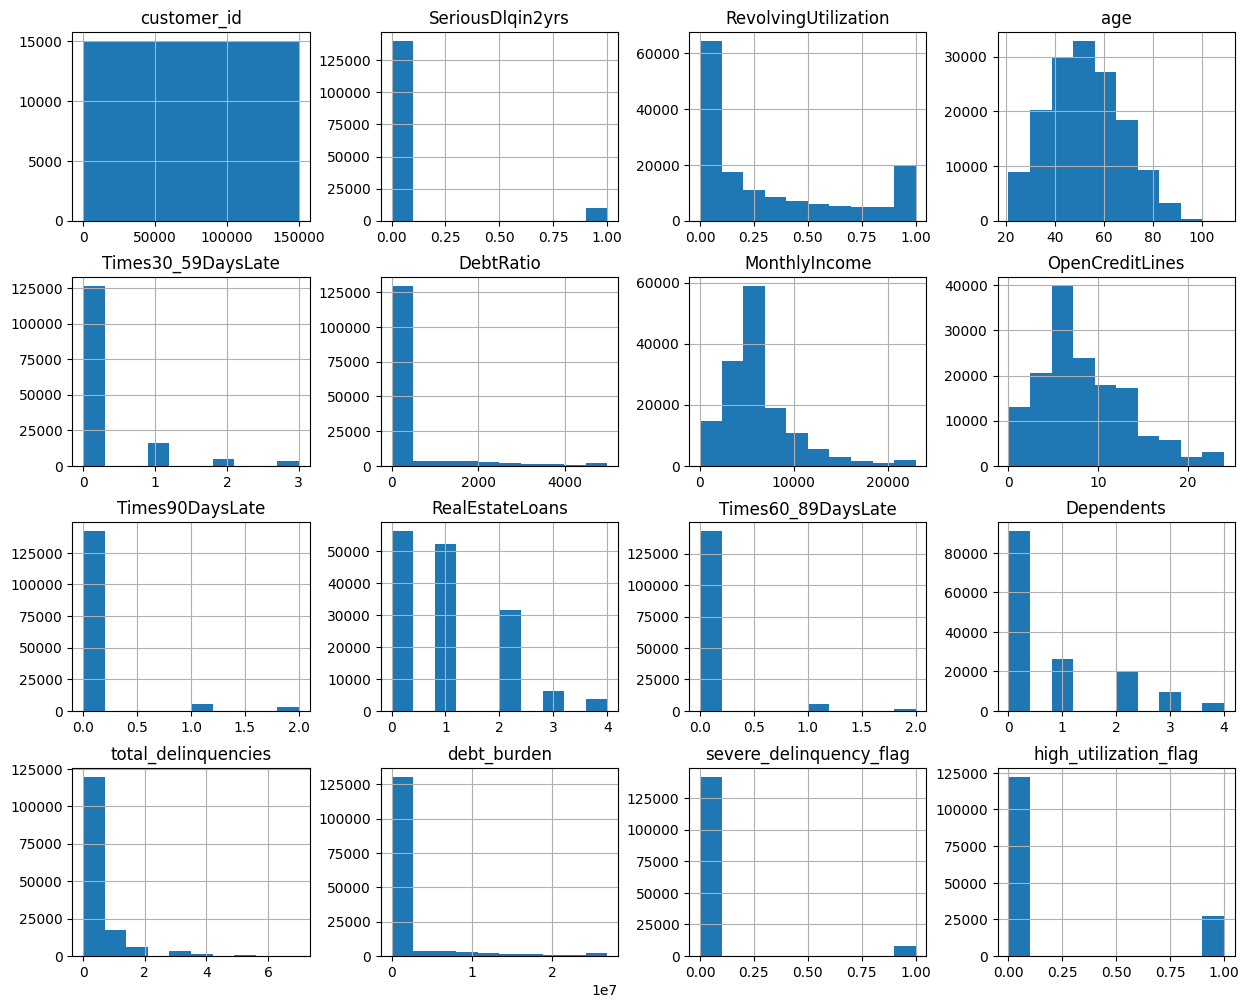

In [ ]:
#Histogram
df.hist(figsize=(15,12))

plt.show()

In [ ]:
#Creating Age Groups
df["AgeGroup"] = pd.cut(
    df["age"],
    bins=[0,30,45,60,150],
    labels=["Under 30","30-45","46-60","Above 60"]
)

In [ ]:
#Default Rate by Age
df.groupby("AgeGroup")["SeriousDlqin2yrs"].mean()*100

/tmp/ipykernel_993/3177529089.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("AgeGroup")["SeriousDlqin2yrs"].mean()*100


,SeriousDlqin2yrs
AgeGroup,
Under 30,11.564563
30-45,9.310183
46-60,6.818309
Above 60,2.996005


In [ ]:
#Creating age group tables with their default rate
age_summary = df.groupby("AgeGroup").agg(
    total_customers=("customer_id","count"),
    defaults=("SeriousDlqin2yrs","sum"),
    default_rate=("SeriousDlqin2yrs","mean")
)

age_summary["default_rate"]*=100

age_summary

/tmp/ipykernel_993/3337869453.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_summary = df.groupby("AgeGroup").agg(


,total_customers,defaults,default_rate
AgeGroup,,,
Under 30,10757,1244,11.564563
30-45,40547,3775,9.310183
46-60,53635,3657,6.818309
Above 60,45060,1350,2.996005


#Feature Engineering

In [ ]:
#Income Segment
df["income_segment"] = pd.cut(
    df["MonthlyIncome"],
    bins=[0,3000,6000,10000,float("inf")],
    labels=["Low","Mid","High","Very High"]
)

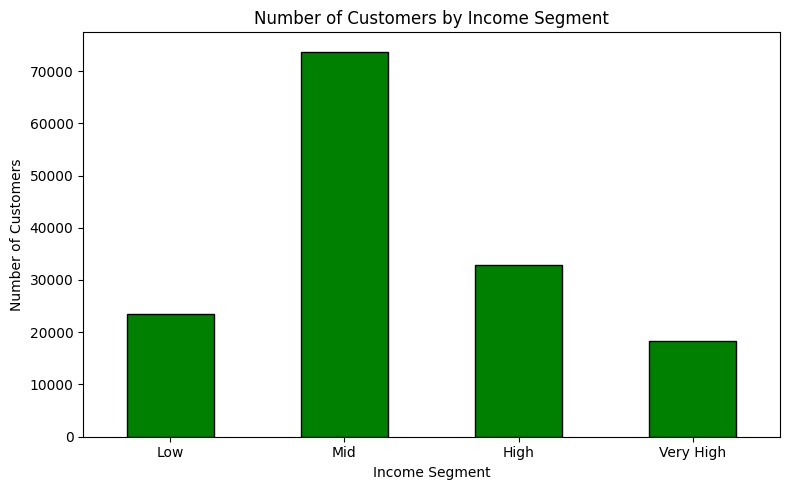

In [ ]:
income_summary = df.groupby("income_segment", observed=False).agg(
    customers=("customer_id","count"),
    defaults=("SeriousDlqin2yrs","sum"),
    default_rate=("SeriousDlqin2yrs","mean")
)

income_summary["default_rate"]*=100

plt.figure(figsize=(8, 5))

income_summary['customers'].plot(
    kind='bar',
    color='green',
    edgecolor='black'
)

plt.title("Number of Customers by Income Segment")
plt.ylabel("Number of Customers")
plt.xlabel("Income Segment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#Risk Segmentation
risk_summary = df.groupby(
    ["severe_delinquency_flag","high_utilization_flag"]
).agg(
    customers=("customer_id","count"),
    defaults=("SeriousDlqin2yrs","sum"),
    default_rate=("SeriousDlqin2yrs","mean")
)

risk_summary["default_rate"]*=100

risk_summary

customers  defaults  \
severe_delinquency_flag high_utilization_flag                        
0                       0                         119489      3486   
                        1                          22436      3211   
1                       0                           2987       895   
                        1                           5087      2434   

                                               default_rate  
severe_delinquency_flag high_utilization_flag                
0                       0                          2.917423  
                        1                         14.311820  
1                       0                         29.963174  
                        1                         47.847454

In [ ]:
#Income Segment Analysis
income_summary = df.groupby("income_segment").agg(
    customers=("customer_id","count"),
    defaults=("SeriousDlqin2yrs","sum"),
    default_rate=("SeriousDlqin2yrs","mean")
)

income_summary["default_rate"]*=100

income_summary

/tmp/ipykernel_993/2314814061.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_summary = df.groupby("income_segment").agg(


,customers,defaults,default_rate
income_segment,,,
Low,23450,2211,9.428571
Mid,73720,5123,6.949267
High,32876,1834,5.578538
Very High,18319,792,4.323380


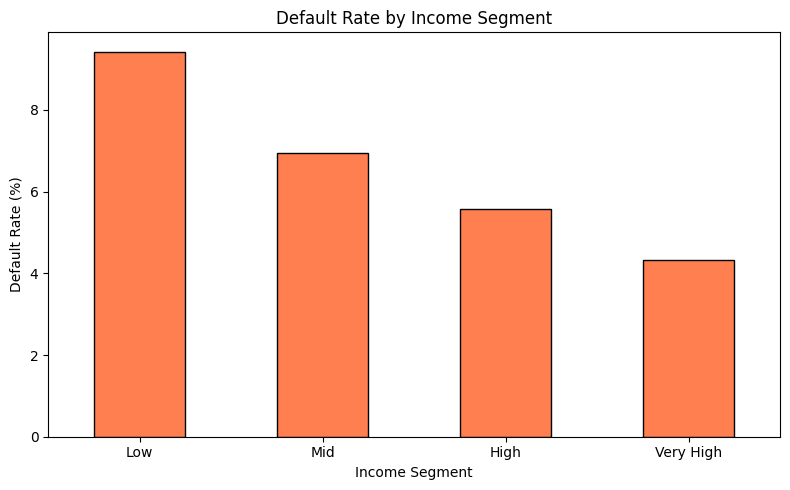

✅ Clean data saved!
Final shape: (149999, 16)
Columns: ['customer_id', 'SeriousDlqin2yrs', 'RevolvingUtilization', 'age', 'Times30_59DaysLate', 'DebtRatio', 'MonthlyIncome', 'OpenCreditLines', 'Times90DaysLate', 'RealEstateLoans', 'Times60_89DaysLate', 'Dependents', 'total_delinquencies', 'debt_burden', 'severe_delinquency_flag', 'high_utilization_flag']


In [ ]:
# Income default rate plot
plt.figure(figsize=(8, 5))
income_summary['default_rate'].plot(
    kind='bar', color='coral', edgecolor='black')
plt.title("Default Rate by Income Segment")
plt.ylabel("Default Rate (%)")
plt.xlabel("Income Segment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Drop all temporary columns now that analysis is done
cols_to_drop = ['age_group', 'AgeGroup', 'income_segment']
df.drop(columns=[c for c in cols_to_drop if c in df.columns],
        inplace=True)

# Save clean CSV — all cleaning and feature engineering complete
df.to_csv('credit_risk_clean.csv', index=False)
print("✅ Clean data saved!")
print("Final shape:", df.shape)
print("Columns:", df.columns.tolist())

### Phase 3: Weight of Evidence & Information Value

In [ ]:
import sys
!{sys.executable} -m pip install scorecardpy

import scorecardpy as sc
import warnings
warnings.filterwarnings('ignore')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 722.8 kB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for scorecardpy: filename=scorecardpy-0.1.9.7-py3-none-any.whl size=60629 sha256=6c16c415bc9a2b542f81e457b92781e5bc22bc71c34ad8810773214fbfad6850
  Stored in directory: /root/.cache/pip/wheels/9f/d8/4e/61a6f4e78fe6700f66b699ab38377f0aa5b33e3ef55751ba38
Successfully built scorecardpy


In [ ]:
# Load your clean data from Phase 2
df = pd.read_csv('/content/credit_risk_clean.csv')

print("Shape:", df.shape)
print("Default rate:", df['SeriousDlqin2yrs'].mean() * 100, "%")

Shape: (149999, 16)
Default rate: 6.684044560297068 %


In [ ]:
# Target variable
target = 'SeriousDlqin2yrs'

# Features to evaluate
# Drop customer_id and derived flag columns for WoE analysis
features = ['RevolvingUtilization', 'age', 'Times30_59DaysLate',
            'DebtRatio', 'MonthlyIncome', 'OpenCreditLines',
            'Times90DaysLate', 'RealEstateLoans',
            'Times60_89DaysLate', 'Dependents']

# Working dataframe
df_woe = df[features + [target]].copy()

print("Features for WoE analysis:", len(features))
print(df_woe.shape)

Features for WoE analysis: 10
(149999, 11)


In [ ]:
# Automatic binning
bins = sc.woebin(df_woe, y=target)

# View bins for each variable
for col in features:
    print(f"\n{'='*50}")
    print(f"Variable: {col}")
    print(bins[col])

[INFO] creating woe binning ...
Binning on 149999 rows and 11 columns in 00:00:22

Variable: RevolvingUtilization
               variable          bin  count  count_distr   good   bad  \
0  RevolvingUtilization  [-inf,0.14)  72559     0.483730  71200  1359   
1  RevolvingUtilization   [0.14,0.5)  36153     0.241022  34525  1628   
2  RevolvingUtilization   [0.5,0.86)  19081     0.127208  16909  2172   
3  RevolvingUtilization   [0.86,inf)  22206     0.148041  17339  4867   

    badprob       woe    bin_iv  total_iv breaks  is_special_values  
0  0.018730 -1.322476  0.493445  1.078472   0.14              False  
1  0.045031 -0.418064  0.035233  1.078472    0.5              False  
2  0.113831  0.584070  0.055974  1.078472   0.86              False  
3  0.219175  1.365787  0.493819  1.078472    inf              False  

Variable: age
  variable          bin  count  count_distr   good   bad   badprob       woe  \
0      age  [-inf,44.0)  44508     0.296722  40015  4493  0.100948  0.44953

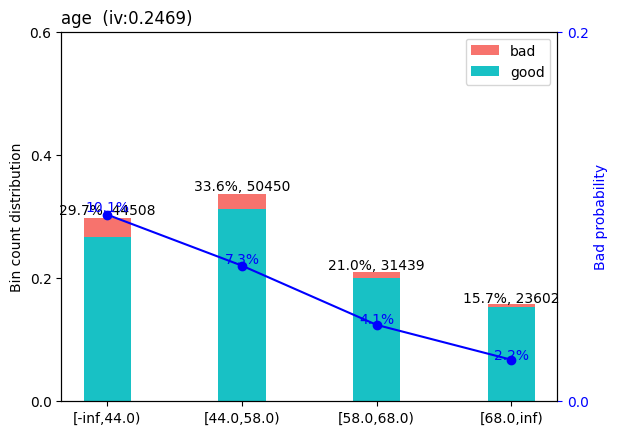

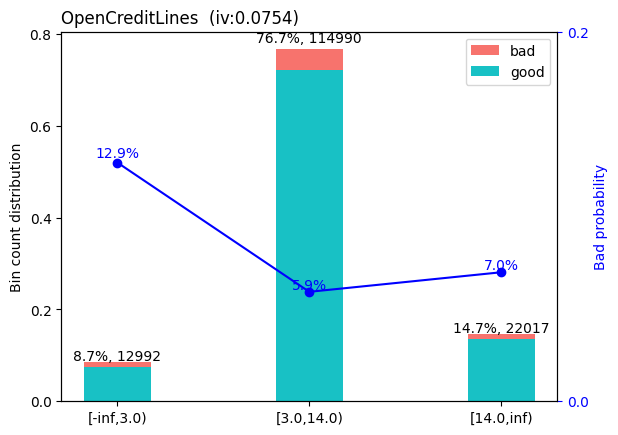

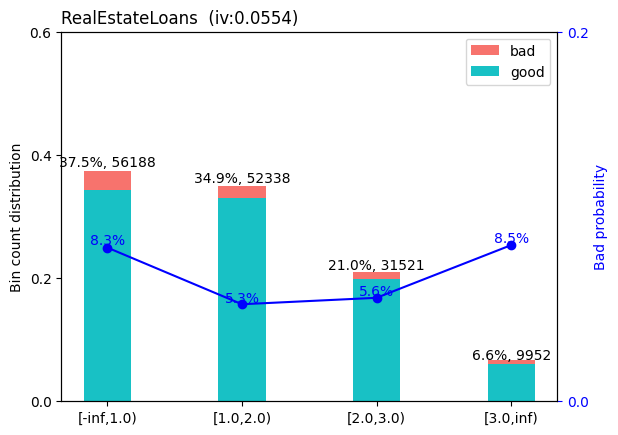

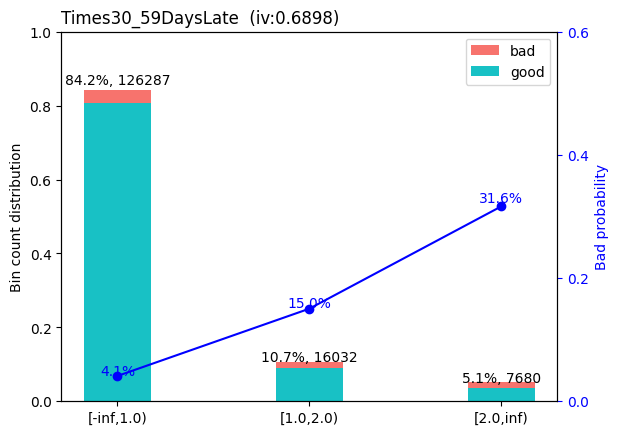

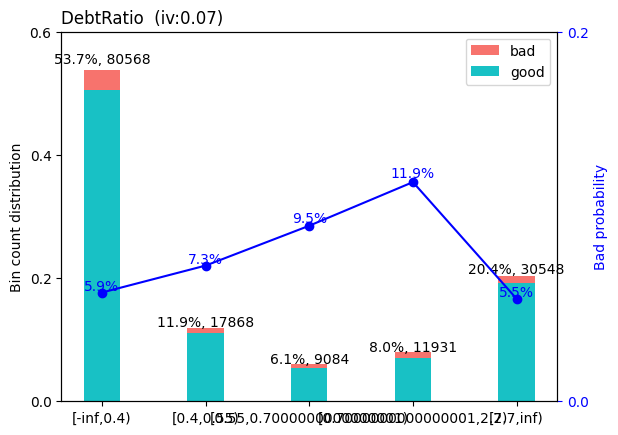

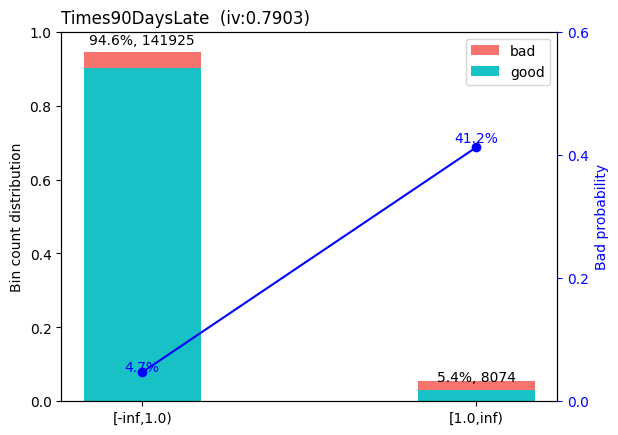

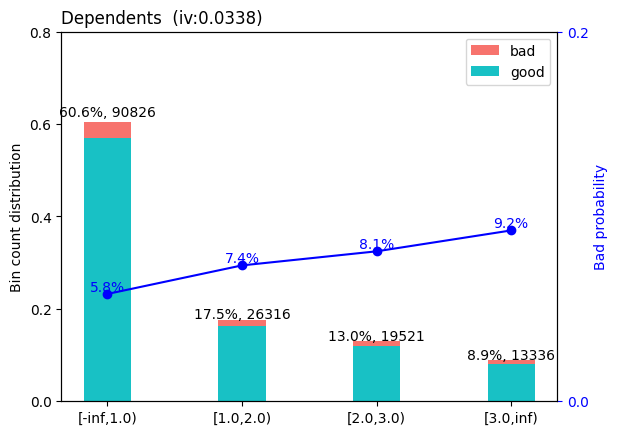

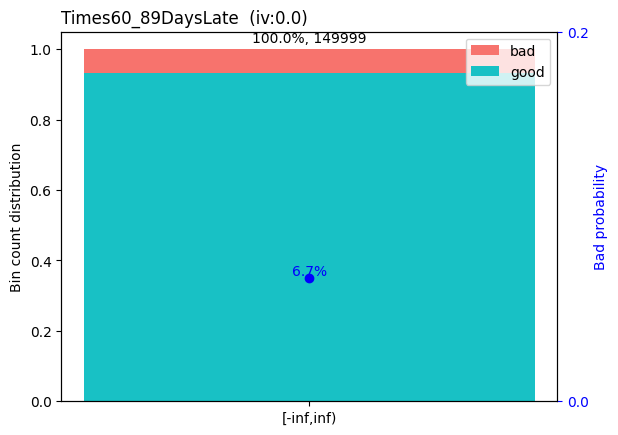

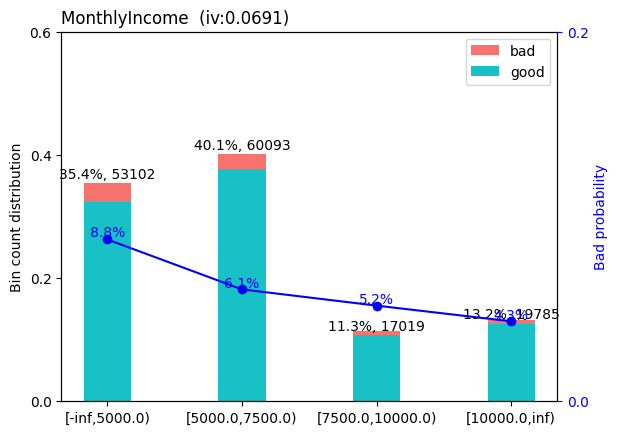

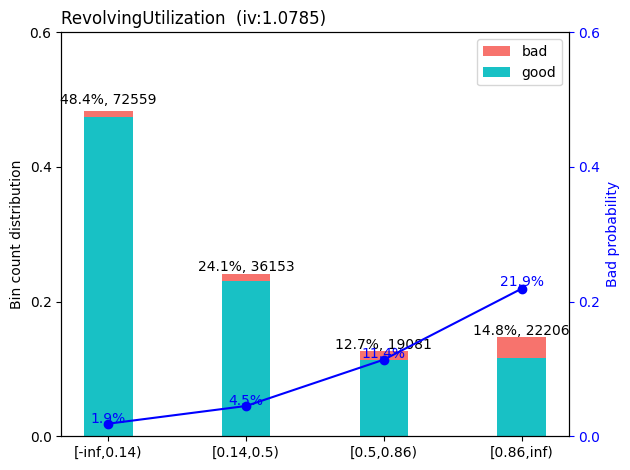

,customers,defaults,default_rate
income_segment,,,
Low,23450,2211,9.428571
Mid,73720,5123,6.949267
High,32876,1834,5.578538
Very High,18319,792,4.323380


In [ ]:
# Plot WoE for all variables
sc.woebin_plot(bins)
plt.tight_layout()
plt.show()

income_summary

In [ ]:
# Extract IV for each variable
iv_values = {}

for col in features:
    iv_values[col] = bins[col]['total_iv'].iloc[0]

# Create IV summary table
iv_df = pd.DataFrame({
    'Variable': list(iv_values.keys()),
    'IV': list(iv_values.values())
}).sort_values('IV', ascending=False).reset_index(drop=True)

# Add predictive power label
def iv_label(iv):
    if iv < 0.02:
        return 'Useless'
    elif iv < 0.1:
        return 'Weak'
    elif iv < 0.3:
        return 'Medium'
    elif iv < 0.5:
        return 'Strong'
    else:
        return 'Suspicious'

iv_df['Predictive_Power'] = iv_df['IV'].apply(iv_label)

print(iv_df)

               Variable        IV Predictive_Power
0  RevolvingUtilization  1.078472       Suspicious
1       Times90DaysLate  0.790327       Suspicious
2    Times30_59DaysLate  0.689841       Suspicious
3                   age  0.246922           Medium
4       OpenCreditLines  0.075371             Weak
5             DebtRatio  0.070049             Weak
6         MonthlyIncome  0.069051             Weak
7       RealEstateLoans  0.055351             Weak
8            Dependents  0.033822             Weak
9    Times60_89DaysLate  0.000000          Useless


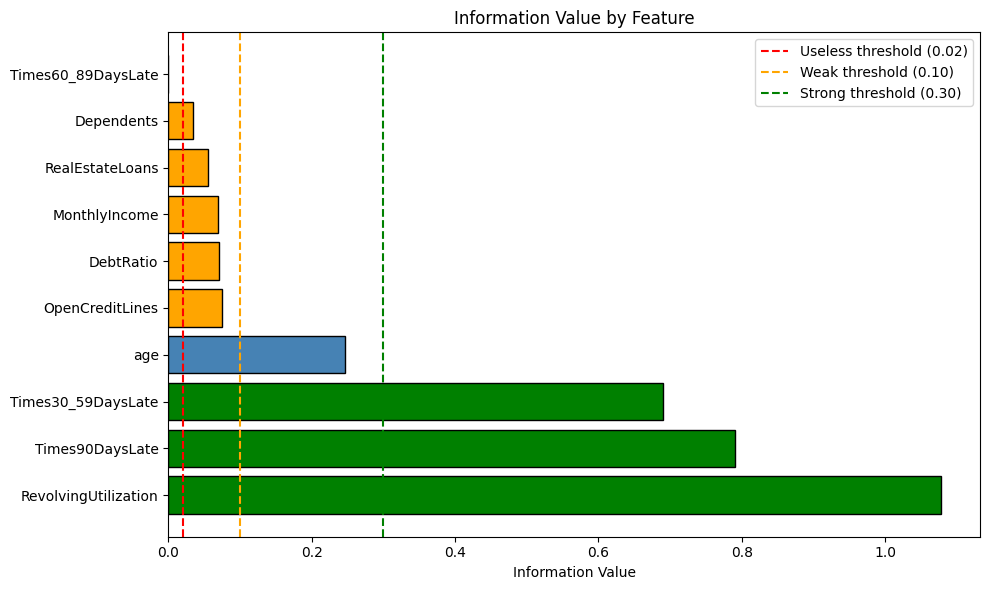

In [ ]:
plt.figure(figsize=(10, 6))
colors = ['red' if iv < 0.02 else 'orange' if iv < 0.1
          else 'steelblue' if iv < 0.3 else 'green'
          for iv in iv_df['IV']]

plt.barh(iv_df['Variable'], iv_df['IV'], color=colors, edgecolor='black')
plt.axvline(x=0.02, color='red', linestyle='--', label='Useless threshold (0.02)')
plt.axvline(x=0.1, color='orange', linestyle='--', label='Weak threshold (0.10)')
plt.axvline(x=0.3, color='green', linestyle='--', label='Strong threshold (0.30)')
plt.xlabel("Information Value")
plt.title("Information Value by Feature")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Keep only variables with IV >= 0.02 (drop useless ones)
selected_features = iv_df[iv_df['IV'] >= 0.02]['Variable'].tolist()

print("Features selected:", selected_features)
print("Features dropped:",
      [f for f in features if f not in selected_features])

# Handle suspicious IV (>0.5) — check for data leakage
suspicious = iv_df[iv_df['IV'] > 0.5]['Variable'].tolist()
if suspicious:
    print("\nCheck these for data leakage:", suspicious)

Features selected: ['RevolvingUtilization', 'Times90DaysLate', 'Times30_59DaysLate', 'age', 'OpenCreditLines', 'DebtRatio', 'MonthlyIncome', 'RealEstateLoans', 'Dependents']
Features dropped: ['Times60_89DaysLate']

Check these for data leakage: ['RevolvingUtilization', 'Times90DaysLate', 'Times30_59DaysLate']


In [ ]:
# Apply WoE transformation to selected features only
df_woe_transformed = sc.woebin_ply(df_woe, bins)

print("WoE transformed dataframe shape:", df_woe_transformed.shape)
print(df_woe_transformed.head())

# Column names will now be: variable_woe
# e.g. RevolvingUtilization_woe, age_woe etc.

[INFO] converting into woe values ...
Woe transformating on 149999 rows and 10 columns in 00:00:11
WoE transformed dataframe shape: (149999, 11)
   SeriousDlqin2yrs   age_woe  OpenCreditLines_woe  RealEstateLoans_woe  \
0                 1  0.100370             -0.12898             0.253622   
1                 0  0.449534             -0.12898             0.235963   
2                 0  0.449534              0.72783             0.235963   
3                 0  0.449534             -0.12898             0.235963   
4                 0  0.100370             -0.12898            -0.256648   

   Times30_59DaysLate_woe  DebtRatio_woe  Times90DaysLate_woe  Dependents_woe  \
0                1.865329       0.630499            -0.369035        0.209356   
1               -0.513992      -0.135939            -0.369035        0.102571   
2                0.903720      -0.135939             2.281848       -0.150067   
3               -0.513992      -0.135939            -0.369035       -0.150067   

WoE transformed columns:
       RevolvingUtilization_woe  Times90DaysLate_woe  Times30_59DaysLate_woe  \
count             149999.000000        149999.000000           149999.000000   
mean                  -0.463993            -0.226346               -0.240644   
std                    0.996195             0.598243                0.655712   
min                   -1.322476            -0.369035               -0.513992   
25%                   -1.322476            -0.369035               -0.513992   
50%                   -0.418064            -0.369035               -0.513992   
75%                    0.584070            -0.369035               -0.513992   
max                    1.365787             2.281848                1.865329   

             age_woe  OpenCreditLines_woe  DebtRatio_woe  MonthlyIncome_woe  \
count  149999.000000        149999.000000  149999.000000      149999.000000   
mean       -0.117797            -0.028989      -0.028055          -0.030154   
std         0.553

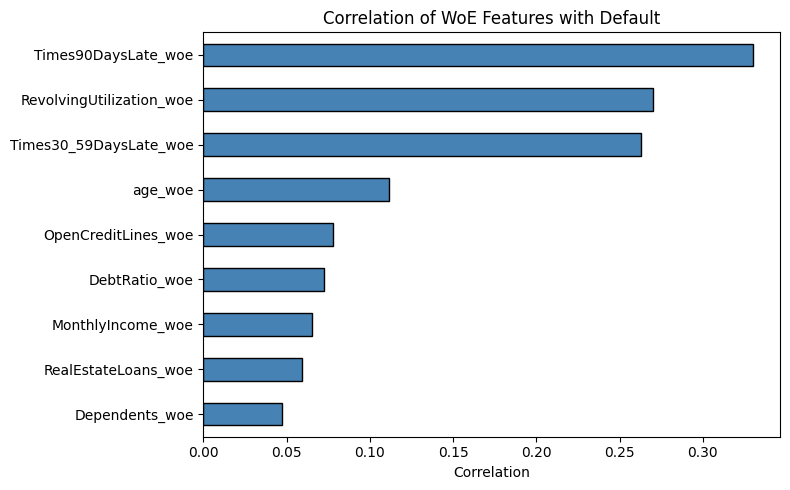

In [ ]:
# Check WoE transformed columns
woe_cols = [col + '_woe' for col in selected_features]

print("WoE transformed columns:")
print(df_woe_transformed[woe_cols].describe())

# Check correlation of WoE features with target
correlations = df_woe_transformed[woe_cols].corrwith(
    df_woe_transformed[target]).sort_values()

plt.figure(figsize=(8, 5))
correlations.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title("Correlation of WoE Features with Default")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

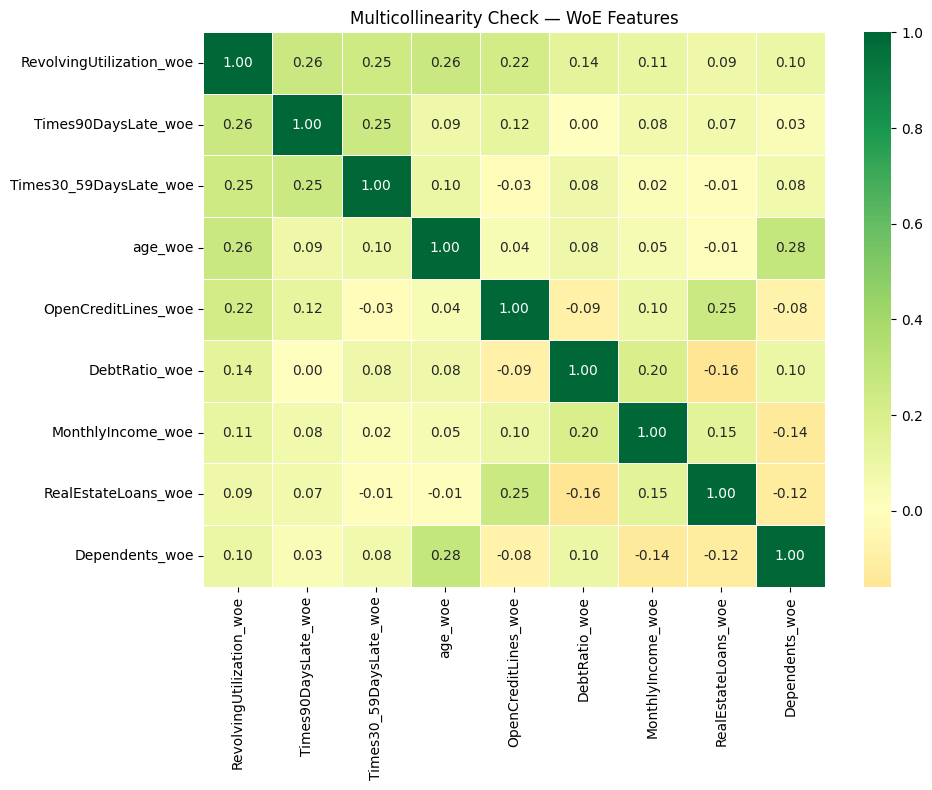

No multicollinearity issues found


In [ ]:
# Correlation between WoE features
# High correlation between features = multicollinearity problem

plt.figure(figsize=(10, 8))
corr_matrix = df_woe_transformed[woe_cols].corr()

sns.heatmap(corr_matrix,
            annot=True,
            fmt='.2f',
            cmap='RdYlGn',
            center=0,
            linewidths=0.5)

plt.title("Multicollinearity Check — WoE Features")
plt.tight_layout()
plt.show()

# Flag highly correlated pairs (>0.7)
high_corr = []
for i in range(len(woe_cols)):
    for j in range(i+1, len(woe_cols)):
        if abs(corr_matrix.iloc[i,j]) > 0.7:
            high_corr.append({
                'Feature 1': woe_cols[i],
                'Feature 2': woe_cols[j],
                'Correlation': round(corr_matrix.iloc[i,j], 2)
            })

if high_corr:
    print("Highly correlated pairs — consider dropping one:")
    print(pd.DataFrame(high_corr))
else:
    print("No multicollinearity issues found")

In [ ]:
# Keep only selected WoE features + target
final_cols = [col + '_woe' for col in selected_features] + [target]
df_final = df_woe_transformed[final_cols].copy()

print("Final dataset shape:", df_final.shape)
print("Features going into model:", selected_features)

# Save
df_final.to_csv('credit_risk_woe.csv', index=False)
print("WoE transformed data saved!")

# Also save bins for later use in scorecard
import pickle
with open('woe_bins.pkl', 'wb') as f:
    pickle.dump(bins, f)
print("WoE bins saved for scorecard conversion!")

Final dataset shape: (149999, 10)
Features going into model: ['RevolvingUtilization', 'Times90DaysLate', 'Times30_59DaysLate', 'age', 'OpenCreditLines', 'DebtRatio', 'MonthlyIncome', 'RealEstateLoans', 'Dependents']
WoE transformed data saved!
WoE bins saved for scorecard conversion!


#Logistic Regression

In [ ]:
import pickle

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

# Load WoE transformed data
df_final = pd.read_csv('credit_risk_woe.csv')

# Load bins saved in Phase 3
with open('woe_bins.pkl', 'rb') as f:
    bins = pickle.load(f)

print("Shape:", df_final.shape)
print("Default rate:", df_final['SeriousDlqin2yrs'].mean() * 100, "%")

Shape: (149999, 10)
Default rate: 6.684044560297068 %


In [ ]:
# Separate features and target
X = df_final.drop(columns=['SeriousDlqin2yrs'])
y = df_final['SeriousDlqin2yrs']

# Split — stratify ensures same default rate in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print()
print("Train default rate:", round(y_train.mean() * 100, 2), "%")
print("Test default rate:", round(y_test.mean() * 100, 2), "%")
# Both should show ~6.68% — confirms stratification worked

Training set size: (119999, 9)
Test set size: (30000, 9)

Train default rate: 6.68 %
Test default rate: 6.68 %


In [ ]:
# Build model with class_weight='balanced' for imbalance
model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000,
    solver='lbfgs'
)

model.fit(X_train, y_train)
print("Model trained successfully!")

# View coefficients
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print("\nModel Coefficients:")
print(coef_df)

Model trained successfully!

Model Coefficients:
                    Feature  Coefficient
5             DebtRatio_woe     1.040840
7       RealEstateLoans_woe     0.812820
2    Times30_59DaysLate_woe     0.720472
1       Times90DaysLate_woe     0.696342
0  RevolvingUtilization_woe     0.667340
3                   age_woe     0.492275
4       OpenCreditLines_woe     0.308053
8            Dependents_woe     0.165267
6         MonthlyIncome_woe     0.098497


In [ ]:
# Probability predictions
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Binary predictions (using 0.5 threshold)
y_pred = model.predict(X_test)

print("Sample predicted probabilities:")
print(y_pred_proba[:10])
print()
print("Sample binary predictions:")
print(y_pred[:10])

Sample predicted probabilities:
[0.19541603 0.14486145 0.19218867 0.20271908 0.26785907 0.4928993
 0.14512027 0.65038471 0.10437229 0.29567535]

Sample binary predictions:
[0 0 0 0 0 0 0 1 0 0]


In [ ]:
# Class Imbalance Treatment Verification
from sklearn.metrics import classification_report

# Baseline model WITHOUT class_weight balancing
model_baseline = LogisticRegression(random_state=42, max_iter=1000)
model_baseline.fit(X_train, y_train)
y_pred_baseline = model_baseline.predict(X_test)

print("="*50)
print("WITHOUT class_weight (baseline)")
print("="*50)
print(classification_report(y_test, y_pred_baseline))

print("="*50)
print("WITH class_weight='balanced'")
print("="*50)
print(classification_report(y_test, y_pred))

WITHOUT class_weight (baseline)
              precision    recall  f1-score   support

           0       0.94      0.99      0.97     27995
           1       0.52      0.14      0.23      2005

    accuracy                           0.93     30000
   macro avg       0.73      0.57      0.60     30000
weighted avg       0.91      0.93      0.92     30000

WITH class_weight='balanced'
              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27995
           1       0.21      0.77      0.33      2005

    accuracy                           0.79     30000
   macro avg       0.59      0.78      0.60     30000
weighted avg       0.93      0.79      0.84     30000



In [ ]:
!pip install imbalanced-learn

from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

# Apply SMOTE only on training data — never on test data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

# Train a new model on SMOTE-balanced data
model_smote = LogisticRegression(random_state=42, max_iter=1000)
model_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = model_smote.predict(X_test)
y_pred_proba_smote = model_smote.predict_proba(X_test)[:, 1]

print("="*50)
print("WITH SMOTE")
print("="*50)
print(classification_report(y_test, y_pred_smote))
print("AUC:", roc_auc_score(y_test, y_pred_proba_smote))

WITH SMOTE
              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27995
           1       0.21      0.77      0.33      2005

    accuracy                           0.79     30000
   macro avg       0.59      0.78      0.60     30000
weighted avg       0.93      0.79      0.84     30000

AUC: 0.8519930037381988


In [ ]:
# Summary comparison table
from sklearn.metrics import recall_score, precision_score, f1_score

# Calculate y_pred_proba_baseline
y_pred_proba_baseline = model_baseline.predict_proba(X_test)[:, 1]

comparison = pd.DataFrame({
    'Method': ['Baseline (No Balancing)', "class_weight='balanced'", 'SMOTE'],
    'AUC': [
        roc_auc_score(y_test, y_pred_proba_baseline),
        roc_auc_score(y_test, y_pred_proba),
        roc_auc_score(y_test, y_pred_proba_smote)
    ],
    'Recall (Defaulters)': [
        recall_score(y_test, y_pred_baseline),
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_smote)
    ],
    'Precision (Defaulters)': [
        precision_score(y_test, y_pred_baseline),
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_smote)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_baseline),
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_smote)
    ]
})

print(comparison.round(4))

                    Method     AUC  Recall (Defaulters)  \
0  Baseline (No Balancing)  0.8518               0.1441   
1  class_weight='balanced'  0.8519               0.7651   
2                    SMOTE  0.8520               0.7666   

   Precision (Defaulters)  F1 Score  
0                  0.5152    0.2253  
1                  0.2098    0.3293  
2                  0.2085    0.3278  


ROC AUC Score: 0.8519


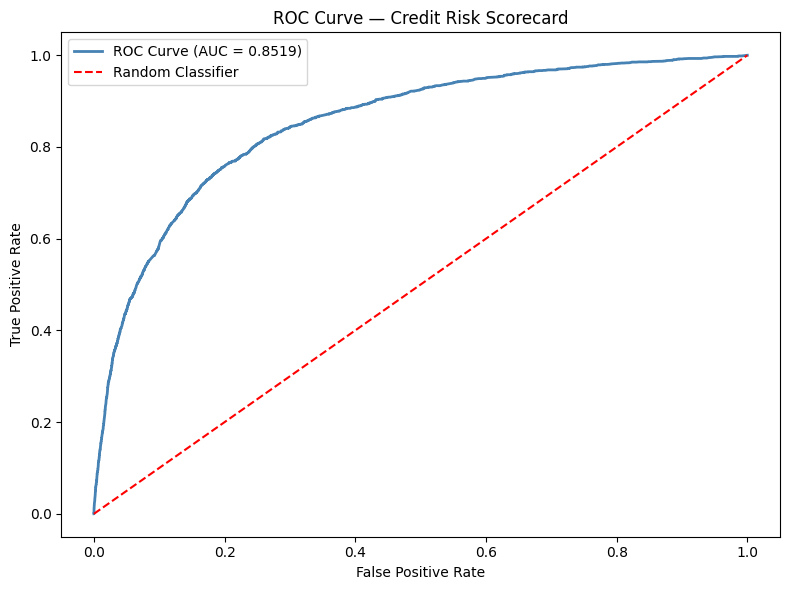

In [ ]:
# ROC AUC
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"ROC AUC Score: {auc_score:.4f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='steelblue',
         linewidth=2, label=f'ROC Curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='red',
         linestyle='--', label='Random Classifier')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Credit Risk Scorecard")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Gini = 2*AUC - 1
gini = 2 * auc_score - 1
print(f"Gini Coefficient: {gini:.4f}")

Gini Coefficient: 0.7038


KS Statistic: 0.5600
KS P-value: 0.000000


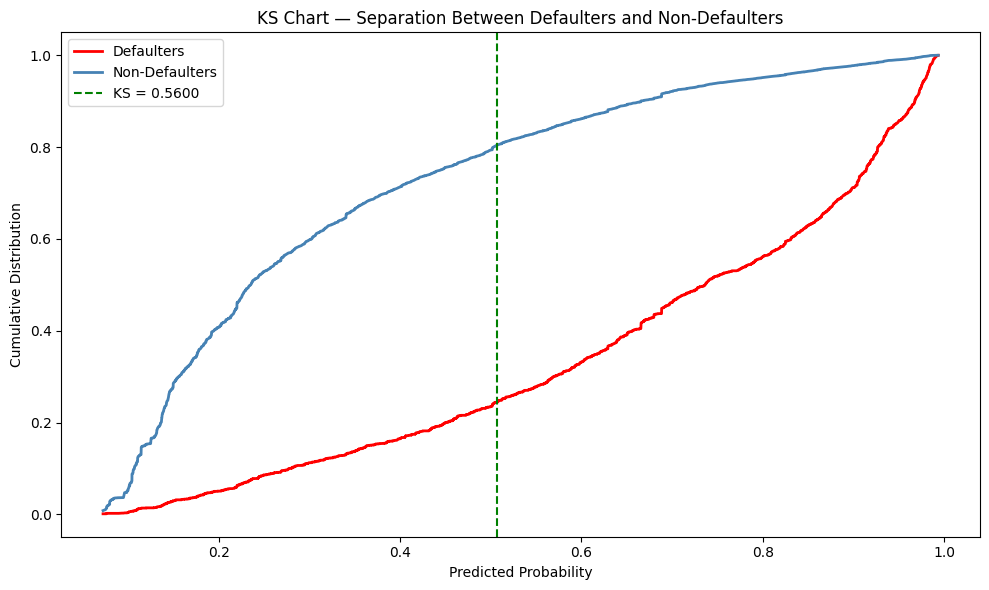

In [ ]:
# KS Statistic calculation
from scipy import stats

# Separate scores for defaulters and non-defaulters
defaulters = y_pred_proba[y_test == 1]
non_defaulters = y_pred_proba[y_test == 0]

# KS test
ks_stat, ks_pvalue = stats.ks_2samp(defaulters, non_defaulters)
print(f"KS Statistic: {ks_stat:.4f}")
print(f"KS P-value: {ks_pvalue:.6f}")

# Plot KS chart
plt.figure(figsize=(10, 6))

# Sort and compute CDFs
sorted_scores = np.sort(y_pred_proba)
cdf_defaulters = np.searchsorted(
    np.sort(defaulters), sorted_scores, side='right') / len(defaulters)
cdf_non_defaulters = np.searchsorted(
    np.sort(non_defaulters), sorted_scores, side='right') / len(non_defaulters)

plt.plot(sorted_scores, cdf_defaulters,
         color='red', linewidth=2, label='Defaulters')
plt.plot(sorted_scores, cdf_non_defaulters,
         color='steelblue', linewidth=2, label='Non-Defaulters')

# Mark KS gap
ks_x = sorted_scores[np.argmax(
    np.abs(cdf_defaulters - cdf_non_defaulters))]
plt.axvline(x=ks_x, color='green',
            linestyle='--', label=f'KS = {ks_stat:.4f}')

plt.xlabel("Predicted Probability")
plt.ylabel("Cumulative Distribution")
plt.title("KS Chart — Separation Between Defaulters and Non-Defaulters")
plt.legend()
plt.tight_layout()
plt.show()

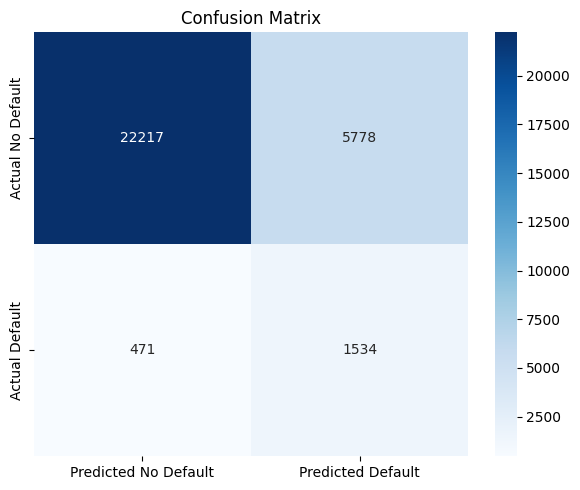

              precision    recall  f1-score   support

           0       0.98      0.79      0.88     27995
           1       0.21      0.77      0.33      2005

    accuracy                           0.79     30000
   macro avg       0.59      0.78      0.60     30000
weighted avg       0.93      0.79      0.84     30000



In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Predicted No Default', 'Predicted Default'],
            yticklabels=['Actual No Default', 'Actual Default'])
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

# Classification report
print(classification_report(y_test, y_pred))

In [ ]:
# 5-fold cross validation — checks model stability
cv_scores = cross_val_score(
    LogisticRegression(class_weight='balanced',
                       random_state=42, max_iter=1000),
    X, y,
    cv=5,
    scoring='roc_auc')

print("Cross Validation AUC Scores:", cv_scores.round(4))
print(f"Mean AUC: {cv_scores.mean():.4f}")
print(f"Std AUC: {cv_scores.std():.4f}")

Cross Validation AUC Scores: [0.8483 0.8438 0.8503 0.8492 0.8555]
Mean AUC: 0.8494
Std AUC: 0.0038


In [ ]:
# Convert logistic regression to scorecard points
# Standard scaling: 600 points = 1:1 odds, 20 points = double the odds

card = sc.scorecard(
    bins,
    model,
    X_train.columns.tolist(),
    points0=600,      # base score
    odds0=1/20,       # base odds
    pdo=20            # points to double odds
)

# View scorecard
for col, card_df in card.items():
    print(f"\n{col}:")
    print(card_df)


basepoints:
     variable  bin  points
0  basepoints  NaN   513.0

RevolvingUtilization:
                variable          bin  points
30  RevolvingUtilization  [-inf,0.14)    25.0
31  RevolvingUtilization   [0.14,0.5)     8.0
32  RevolvingUtilization   [0.5,0.86)   -11.0
33  RevolvingUtilization   [0.86,inf)   -26.0

Times90DaysLate:
           variable         bin  points
19  Times90DaysLate  [-inf,1.0)     7.0
20  Times90DaysLate   [1.0,inf)   -46.0

Times30_59DaysLate:
              variable         bin  points
11  Times30_59DaysLate  [-inf,1.0)    11.0
12  Times30_59DaysLate   [1.0,2.0)   -19.0
13  Times30_59DaysLate   [2.0,inf)   -39.0

age:
  variable          bin  points
0      age  [-inf,44.0)    -6.0
1      age  [44.0,58.0)    -1.0
2      age  [58.0,68.0)     7.0
3      age   [68.0,inf)    16.0

OpenCreditLines:
          variable         bin  points
4  OpenCreditLines  [-inf,3.0)    -6.0
5  OpenCreditLines  [3.0,14.0)     1.0
6  OpenCreditLines  [14.0,inf)    -0.0

DebtRati

In [ ]:
# Load original clean data (before WoE transformation)
df_clean = pd.read_csv('credit_risk_clean.csv')

# Apply scorecard to get credit scores
train_score = sc.scorecard_ply(
    df_clean.iloc[X_train.index],
    card,
    only_total_score=True)

test_score = sc.scorecard_ply(
    df_clean.iloc[X_test.index],
    card,
    only_total_score=True)

print("Train scores summary:")
print(train_score.describe())
print("\nTest scores summary:")
print(test_score.describe())

Train scores summary:
               score
count  119999.000000
mean      534.615355
std        37.480866
min       362.000000
25%       514.000000
50%       545.000000
75%       564.000000
max       586.000000

Test scores summary:
              score
count  30000.000000
mean     534.447533
std       37.391766
min      369.000000
25%      514.000000
50%      544.000000
75%      563.000000
max      586.000000


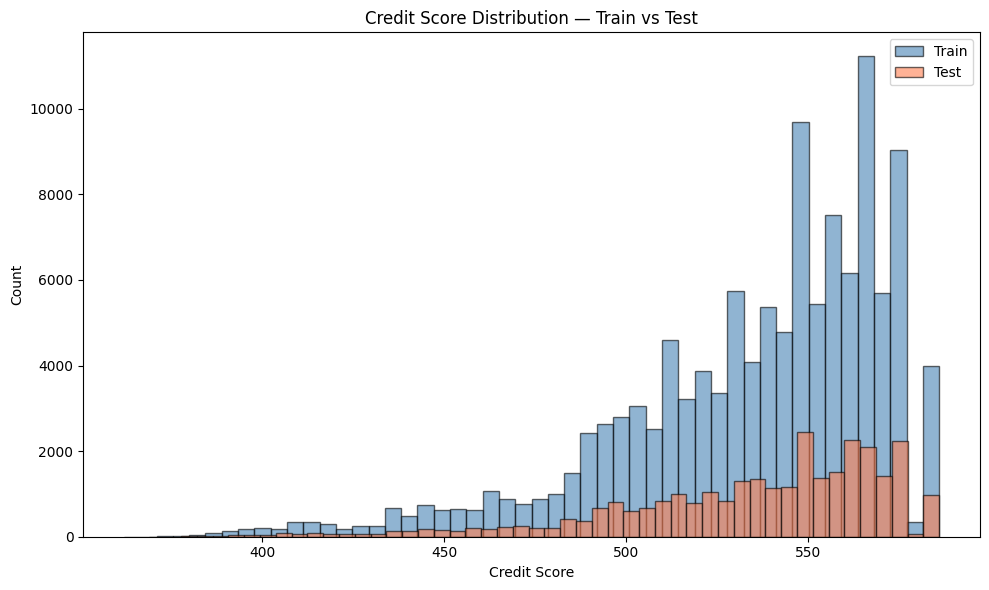

Min score: 369.0
Max score: 586.0
Mean score: 534.0


In [ ]:
# Plot score distribution
plt.figure(figsize=(10, 6))

plt.hist(train_score['score'],
         bins=50,
         alpha=0.6,
         color='steelblue',
         label='Train',
         edgecolor='black')

plt.hist(test_score['score'],
         bins=50,
         alpha=0.6,
         color='coral',
         label='Test',
         edgecolor='black')

plt.xlabel("Credit Score")
plt.ylabel("Count")
plt.title("Credit Score Distribution — Train vs Test")
plt.legend()
plt.tight_layout()
plt.show()

# Score range check
print("Min score:", test_score['score'].min())
print("Max score:", test_score['score'].max())
print("Mean score:", test_score['score'].mean().round(0))

  score_band  total_customers  defaults  default_rate
0       <400              157        96         61.15
1    400-500             4893      1226         25.06
2    500-550            12740       568          4.46
3    550-600            12210       115          0.94
4    600-650                0         0           NaN
5    650-700                0         0           NaN
6       >700                0         0           NaN


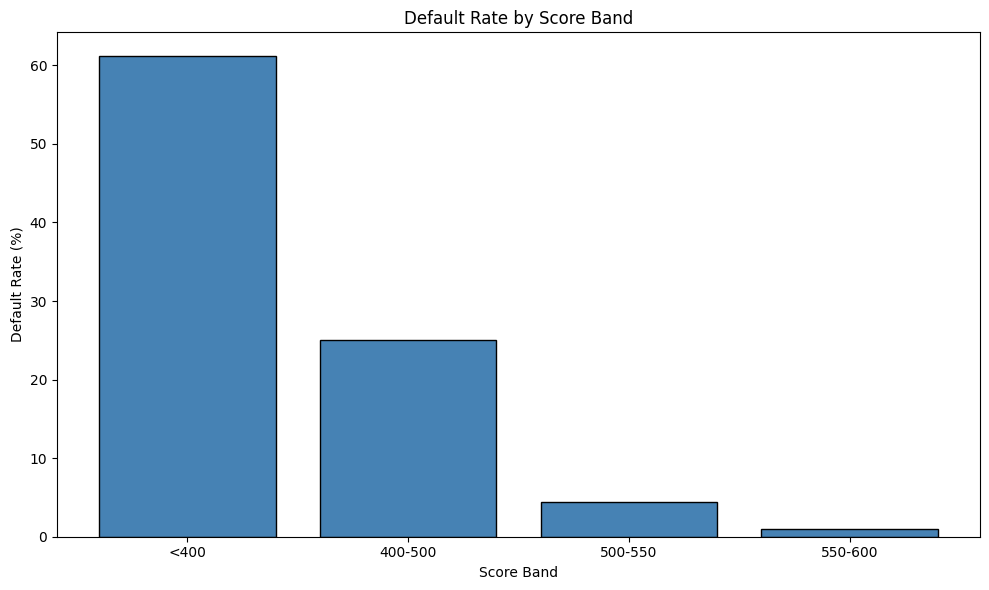

In [ ]:
# Create score bands and check default rate per band
test_score['actual_default'] = y_test.values

test_score['score_band'] = pd.cut(
    test_score['score'],
    bins=[0, 400, 500, 550, 600, 650, 700, 850],
    labels=['<400', '400-500', '500-550',
            '550-600', '600-650', '650-700', '>700'])

band_analysis = test_score.groupby('score_band').agg(
    total_customers=('actual_default', 'count'),
    defaults=('actual_default', 'sum'),
    default_rate=('actual_default', 'mean')
).reset_index()

band_analysis['default_rate'] = (
    band_analysis['default_rate'] * 100).round(2)

print(band_analysis)

# Plot default rate by score band
plt.figure(figsize=(10, 6))
plt.bar(band_analysis['score_band'].astype(str),
        band_analysis['default_rate'],
        color='steelblue',
        edgecolor='black')
plt.xlabel("Score Band")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Score Band")
plt.tight_layout()
plt.show()

In [ ]:
# Add predicted risk category for better dashboard storytelling
test_score['risk_category'] = pd.cut(
    test_score['score'],
    bins=[0, 500, 650, 850],
    labels=['High Risk', 'Medium Risk', 'Low Risk'])

# Merge back original features for richer dashboard filtering
df_clean = pd.read_csv('credit_risk_clean.csv')
test_score_enriched = test_score.merge(
    df_clean[['customer_id', 'age', 'MonthlyIncome',
              'RevolvingUtilization', 'DebtRatio']],
    left_index=True, right_on='customer_id',
    how='left')

test_score_enriched.to_csv('scored_customers_final.csv', index=False)
print("Enriched file saved for Power BI!")
print(test_score_enriched.head())

Enriched file saved for Power BI!
          score  actual_default score_band risk_category  customer_id   age  \
104529.0  554.0               0    550-600   Medium Risk       104531  53.0   
98809.0   563.0               0    550-600   Medium Risk        98811  71.0   
41146.0   554.0               0    550-600   Medium Risk        41147  41.0   
16523.0   552.0               0    550-600   Medium Risk        16524  86.0   
120154.0  543.0               0    500-550   Medium Risk       120156  60.0   

          MonthlyIncome  RevolvingUtilization  DebtRatio  
104529.0         9333.0              0.111809   0.249089  
98809.0         10500.0              0.026423   0.212551  
41146.0          6000.0              0.842846   0.520080  
16523.0          5400.0              0.039570  24.000000  
120154.0         7782.0              0.328946   0.010150  


In [ ]:
test_score_enriched['AgeGroup'] = pd.cut(
    test_score_enriched['age'],
    bins=[0, 30, 45, 60, 120],
    labels=['Under 30', '30-45', '46-60', 'Above 60'])

test_score_enriched['IncomeBracket'] = pd.cut(
    test_score_enriched['MonthlyIncome'],
    bins=[0, 3000, 6000, 10000, float('inf')],
    labels=['Low', 'Mid', 'High', 'Very High'])

test_score_enriched.to_csv('scored_customers_final.csv', index=False)
print(test_score_enriched.shape)
print(test_score_enriched.columns.tolist())

(30000, 11)
['score', 'actual_default', 'score_band', 'risk_category', 'customer_id', 'age', 'MonthlyIncome', 'RevolvingUtilization', 'DebtRatio', 'AgeGroup', 'IncomeBracket']


In [ ]:
print(test_score_enriched[['age', 'MonthlyIncome', 'RevolvingUtilization', 'DebtRatio']].isnull().sum())

age                     1
MonthlyIncome           1
RevolvingUtilization    1
DebtRatio               1
dtype: int64


In [ ]:
print(test_score_enriched.shape)

(30000, 11)


In [ ]:
# Save model
with open('credit_risk_model.pkl', 'wb') as f:
    pickle.dump(model, f)

# Save scorecard
with open('credit_risk_scorecard.pkl', 'wb') as f:
    pickle.dump(card, f)

# Save scored test data for Power BI
test_score.to_csv('scored_customers.csv', index=False)

print("Model saved!")
print("Scorecard saved!")
print("Scored data saved for Power BI!")

Model saved!
Scorecard saved!
Scored data saved for Power BI!


In [ ]:
print("="*40)
print("MODEL PERFORMANCE SUMMARY")
print("="*40)
print(f"ROC AUC:          {auc_score:.4f}")
print(f"Gini Coefficient: {gini:.4f}")
print(f"KS Statistic:     {ks_stat:.4f}")
print(f"CV Mean AUC:      {cv_scores.mean():.4f}")
print(f"CV Std AUC:       {cv_scores.std():.4f}")
print("="*40)

MODEL PERFORMANCE SUMMARY
ROC AUC:          0.8519
Gini Coefficient: 0.7038
KS Statistic:     0.5600
CV Mean AUC:      0.8494
CV Std AUC:       0.0038


#Challenger Model

In [ ]:
!pip install xgboost

from xgboost import XGBClassifier

In [ ]:
# Handle the same 14:1 imbalance XGBoost's way
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(scale_pos_weight, 2))

xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='auc'
)

xgb_model.fit(X_train, y_train)
print("XGBoost model trained successfully!")

scale_pos_weight: 13.96
XGBoost model trained successfully!


In [ ]:
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]
y_pred_xgb = xgb_model.predict(X_test)

In [ ]:
from sklearn.metrics import roc_auc_score
from scipy import stats

auc_score_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
gini_xgb = 2 * auc_score_xgb - 1

defaulters_xgb = y_pred_proba_xgb[y_test == 1]
non_defaulters_xgb = y_pred_proba_xgb[y_test == 0]
ks_stat_xgb, _ = stats.ks_2samp(defaulters_xgb, non_defaulters_xgb)

print(f"XGBoost AUC:  {auc_score_xgb:.4f}")
print(f"XGBoost Gini: {gini_xgb:.4f}")
print(f"XGBoost KS:   {ks_stat_xgb:.4f}")

XGBoost AUC:  0.8387
XGBoost Gini: 0.6773
XGBoost KS:   0.5324


In [ ]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression (WoE)', 'XGBoost (Challenger)'],
    'AUC': [auc_score, auc_score_xgb],
    'Gini': [gini, gini_xgb],
    'KS': [ks_stat, ks_stat_xgb],
    'Interpretable?': ['Yes — regulatory-friendly', 'Lower — black-box tree ensemble']
})
print(model_comparison)

                       Model       AUC      Gini        KS  \
0  Logistic Regression (WoE)  0.851913  0.703826  0.560005   
1       XGBoost (Challenger)  0.838674  0.677348  0.532444   

                    Interpretable?  
0        Yes — regulatory-friendly  
1  Lower — black-box tree ensemble  


In [ ]:
xgb_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'XGB_Importance': xgb_model.feature_importances_
}).sort_values('XGB_Importance', ascending=False)

print(xgb_importance)

                    Feature  XGB_Importance
1       Times90DaysLate_woe        0.490555
0  RevolvingUtilization_woe        0.245323
2    Times30_59DaysLate_woe        0.154877
5             DebtRatio_woe        0.023104
3                   age_woe        0.020663
4       OpenCreditLines_woe        0.019960
7       RealEstateLoans_woe        0.019704
6         MonthlyIncome_woe        0.013290
8            Dependents_woe        0.012525


#Random Forest (bagging technique)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=200
)

rf_model.fit(X_train, y_train)
print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

auc_score_rf = roc_auc_score(y_test, y_pred_proba_rf)
gini_rf = 2 * auc_score_rf - 1

defaulters_rf = y_pred_proba_rf[y_test == 1]
non_defaulters_rf = y_pred_proba_rf[y_test == 0]
ks_stat_rf, _ = stats.ks_2samp(defaulters_rf, non_defaulters_rf)

print(f"Random Forest AUC:  {auc_score_rf:.4f}")
print(f"Random Forest Gini: {gini_rf:.4f}")
print(f"Random Forest KS:   {ks_stat_rf:.4f}")

Random Forest AUC:  0.7277
Random Forest Gini: 0.4555
Random Forest KS:   0.3746


#AdaBoost (a second, different boosting technique from XGBoost)

In [ ]:
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost doesn't take class_weight directly, so we pass sample weights instead
sample_weights = np.where(y_train == 1, scale_pos_weight, 1)

ada_model = AdaBoostClassifier(random_state=42, n_estimators=200)
ada_model.fit(X_train, y_train, sample_weight=sample_weights)
print("AdaBoost trained successfully!")

AdaBoost trained successfully!


In [ ]:
y_pred_proba_ada = ada_model.predict_proba(X_test)[:, 1]

auc_score_ada = roc_auc_score(y_test, y_pred_proba_ada)
gini_ada = 2 * auc_score_ada - 1

defaulters_ada = y_pred_proba_ada[y_test == 1]
non_defaulters_ada = y_pred_proba_ada[y_test == 0]
ks_stat_ada, _ = stats.ks_2samp(defaulters_ada, non_defaulters_ada)

print(f"AdaBoost AUC:  {auc_score_ada:.4f}")
print(f"AdaBoost Gini: {gini_ada:.4f}")
print(f"AdaBoost KS:   {ks_stat_ada:.4f}")

AdaBoost AUC:  0.8532
AdaBoost Gini: 0.7064
AdaBoost KS:   0.5599


In [ ]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression (WoE)', 'XGBoost', 'Random Forest', 'AdaBoost'],
    'AUC': [auc_score, auc_score_xgb, auc_score_rf, auc_score_ada],
    'Gini': [gini, gini_xgb, gini_rf, gini_ada],
    'KS': [ks_stat, ks_stat_xgb, ks_stat_rf, ks_stat_ada],
    'Type': ['Linear (WoE-based)', 'Boosting (tree ensemble)', 'Bagging (tree ensemble)', 'Boosting (tree ensemble)']
})
print(model_comparison)

                       Model       AUC      Gini        KS  \
0  Logistic Regression (WoE)  0.851913  0.703826  0.560005   
1                    XGBoost  0.838674  0.677348  0.532444   
2              Random Forest  0.727740  0.455481  0.374641   
3                   AdaBoost  0.853216  0.706432  0.559859   

                       Type  
0        Linear (WoE-based)  
1  Boosting (tree ensemble)  
2   Bagging (tree ensemble)  
3  Boosting (tree ensemble)  
